In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo gráfico
sns.set_theme(style="whitegrid")

# Carregar o CSV a partir da pasta data/
df = pd.read_csv('../data/cybersecurity_intrusion_data.csv')

# Inspeção inicial
print(f"Dataset carregado: {df.shape[0]} linhas e {df.shape[1]} colunas.\n")
df.head()

Dataset carregado: 9537 linhas e 11 colunas.



,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0


In [2]:
# 1. Selecionar apenas as colunas numéricas
num_cols = df.select_dtypes(include=np.number).columns

# 2. Criar tabela com média, desvio padrão, min, mediana (50%), max
stats = df[num_cols].describe().T

# 3. Adicionar Skewness (Assimetria) e Kurtosis (Curtose)
stats['skewness'] = df[num_cols].skew()
stats['kurtosis'] = df[num_cols].kurtosis()

# 4. Mostrar a tabela formatada
stats[['mean', 'std', 'min', '50%', 'max', 'skewness', 'kurtosis']]

,mean,std,min,50%,max,skewness,kurtosis
network_packet_size,500.430639,198.379364,64.000000,499.000000,1285.000000,0.096030,-0.180105
login_attempts,4.032086,1.963012,1.000000,4.000000,13.000000,0.596308,0.366988
session_duration,792.745312,786.560144,0.500000,556.277457,7190.392213,2.084617,6.913262
ip_reputation_score,0.331338,0.177175,0.002497,0.314778,0.924299,0.454553,-0.398459
failed_logins,1.517773,1.033988,0.000000,1.000000,5.000000,0.406443,-0.180173
unusual_time_access,0.149942,0.357034,0.000000,0.000000,1.000000,1.961334,1.847219
attack_detected,0.447101,0.497220,0.000000,0.000000,1.000000,0.212825,-1.955116


C:\Users\hugod\AppData\Local\Temp\ipykernel_24712\1418687141.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='attack_detected', y='network_packet_size', data=df, ax=axes[1], palette='Set2')


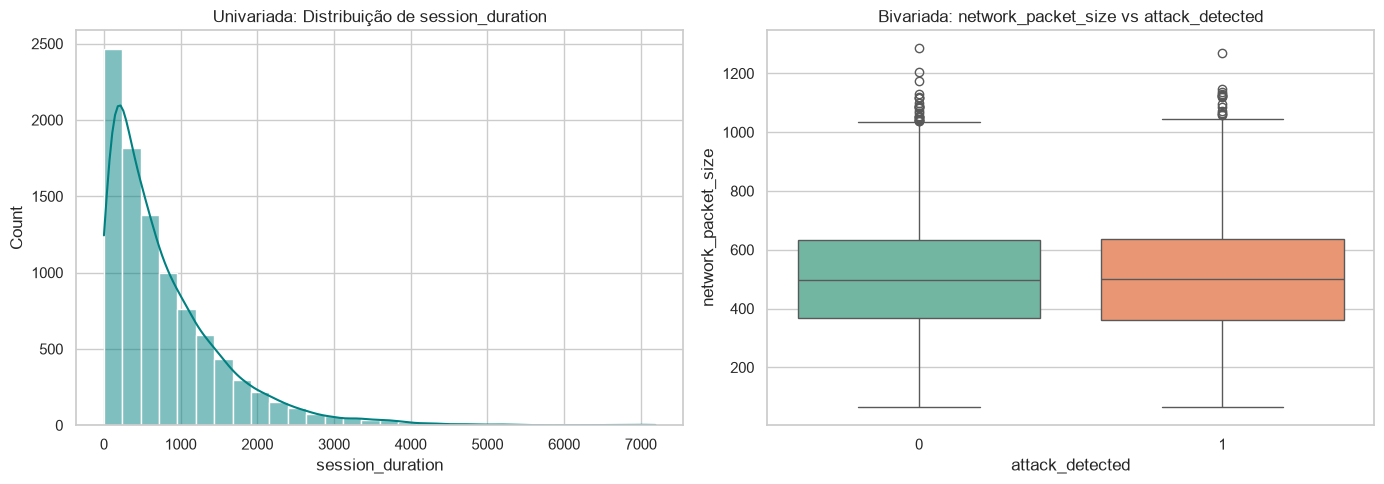

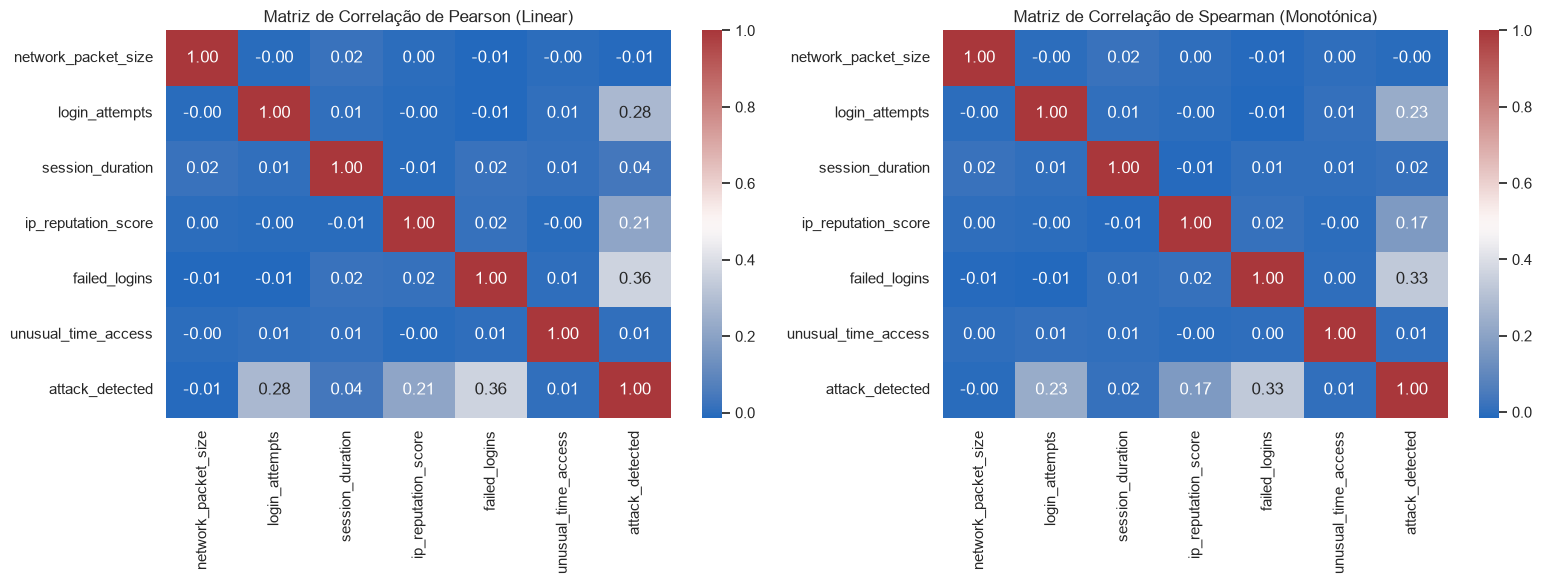

In [3]:
# 1. Visualização Univariada e Bivariada
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma da Duração da Sessão (Univariada)
sns.histplot(df['session_duration'], kde=True, ax=axes[0], color='teal', bins=30)
axes[0].set_title('Univariada: Distribuição de session_duration')

# Boxplot: Tamanho do Pacote vs Ataque Detetado (Bivariada)
sns.boxplot(x='attack_detected', y='network_packet_size', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Bivariada: network_packet_size vs attack_detected')

plt.tight_layout()
plt.show()

# 2. Análise de Correlação (Pearson vs Spearman)
# Remover a coluna target das estatísticas numéricas puras se necessário, ou manter para ver impacto
corr_cols = [c for c in num_cols if c != 'session_id']

corr_pearson = df[corr_cols].corr(method='pearson')
corr_spearman = df[corr_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(corr_pearson, annot=True, fmt='.2f', cmap='vlag', ax=axes[0])
axes[0].set_title('Matriz de Correlação de Pearson (Linear)')

sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='vlag', ax=axes[1])
axes[1].set_title('Matriz de Correlação de Spearman (Monotónica)')

plt.tight_layout()
plt.show()